# Practice guide 1: a spam filter from scratch (Naive Bayes, TF-IDF and logistic regression)

**Goal.** Build the first rungs of the spam ladder yourself: a tokenizer, a Naive Bayes classifier that works in log space,
the evaluation metrics, TF-IDF, and a logistic regression trained by gradient descent with JAX. Every `TODO` cell must be
completed; the `check` cells tell you whether you got it right.

Read `guide_02_01.pdf` first. Time: about 2 hours. Cells marked **(given)** are complete.

In [19]:
from pathlib import Path

import jax
import jax.numpy as jnp
import numpy as np
import polars as pl
import scipy.sparse as sp
from matplotlib import pyplot as plt
from scipy.special import logsumexp
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

jax.config.update("jax_enable_x64", True)

## Part A. Data (given)

SMS Spam Collection: 5,574 messages. Exact duplicates are removed **before** the split, otherwise the same text can sit in both
train and test and inflate the score.

In [20]:
DATA = next(p for p in (Path("../../datasets/spam.csv"), Path("../../../datasets/spam.csv")) if p.exists())  # student / solution folder
df = pl.read_csv(DATA).drop_nulls()
print("raw messages:", df.height)
df = df.unique(subset="SMS", keep="first", maintain_order=True)
texts = [t.replace("�", "£") for t in df["SMS"].to_list()]  # the corpus lost every pound sign
y = (df["Target"] == "spam").cast(pl.Int8).to_numpy()
print("unique messages:", len(texts), " spam ratio:", round(float(y.mean()), 3))

X_txt_train, X_txt_test, y_train, y_test = train_test_split(texts, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_txt_train), len(X_txt_test), int(y_test.sum()))

raw messages: 5521
unique messages: 5119  spam ratio: 0.126
4095 1024 129


**Question A1.** Why do we split *before* building the vocabulary? Why `stratify=y`? (Answer in your report.)

Split = devide dataset into two different parts here. There is the train part and the test part. It's like this to test values, which are not included on the creation of the model. After we can evaluate more accuracy the model.

The stratify parameter is to equilibrate spam and ham classes. When the model are going to be train, this parameter garantee to give the same amount of categories to not have biaised results. 42 is a random number to keep the final result reproductible.


## Part B. The tokenizer

Implement `tokenize(text)`:

1. lower-case the text;
2. replace every run of **5 or more digits** (phone numbers, short codes) by the word `num`;
3. remove the remaining digits;
4. return the list of tokens made of letters `[a-z]+`, **plus** the single characters `£ $ € % !` (strong spam signals).

Example: `"URGENT! Call 09061701461 now, win £100"` $\rightarrow$ `['urgent', '!', 'call', 'num', 'now', 'win', '£']`.

*A tokenizer is a function or component that breaks down raw text (like a sentence or a text message) into a list of smaller pieces called tokens (usually individual words, punctuation marks, or special symbols).*




In [21]:
import re


def tokenize(text):
    text = text.lower();
    print(text)
    # the pattern : r = raw string, \d digital, {5,}
    text = re.sub(r"\d{5,}","num",text)
    print(text)
    # remove all digits 
    text = re.sub(r"\d+"," ",text)
    print(text)
    
    return re.findall(r"[a-z]+|[£$€%!]", text)

print(tokenize("URGENT! Call 09061701461 now, win £100"))

urgent! call 09061701461 now, win £100
urgent! call num now, win £100
urgent! call num now, win £ 
['urgent', '!', 'call', 'num', 'now', 'win', '£']


In [22]:
# check
assert tokenize("URGENT! Call 09061701461 now, win £100") == ["urgent", "!", "call", "num", "now", "win", "£"]
assert tokenize("Ok lar... Joking wif u oni...") == ["ok", "lar", "joking", "wif", "u", "oni"]
print("tokenizer OK")

urgent! call 09061701461 now, win £100
urgent! call num now, win £100
urgent! call num now, win £ 
ok lar... joking wif u oni...
ok lar... joking wif u oni...
ok lar... joking wif u oni...
tokenizer OK


## Part C. The count matrix (given)

The vocabulary contains the words that occur in at least 2 **training** messages. `count_matrix` returns a sparse matrix
(messages x words) of raw counts; out-of-vocabulary words are ignored.

In [23]:
def build_vocab(docs, min_df=2):
    df_ = {}
    # Searching on the model list
    for d in docs:
        # Tokenize the message and explore each word
        # Set allow us to errase multiple show of words
        for w in set(tokenize(d)):
            # For each word, increase a counter on a dimension of the 2D array
            # Here is a dictionnary so every walue have a unique key / It know where to increment when we precise (w,0)
            df_[w] = df_.get(w, 0) + 1
            #print (df_.get(w,0))
    # We save only when the word appear > 1
    # w for w is to extract, on a dictionnary (w,c) (c chelou)
    # sorted take all validate words (so only w but only when >1 apparition)
    return sorted(w for w, c in df_.items() if c >= min_df)


# docs the data of [training or testing] / index constitute of all words 
def count_matrix(docs, index):
    rows, cols, vals = [], [], []
    # explore each message
    for i, d in enumerate(docs):
        # reset counter
        counts = {}
        # tokenize message then explore it
        for w in tokenize(d):
            j = index.get(w)
            if j is not None:
                # word DETECTED
                counts[j] = counts.get(j, 0) + 1
        rows += [i] * len(counts)
        cols += counts.keys()
        vals += counts.values()
    # return the matrix
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(docs), len(index)), dtype=np.float64)


vocab = build_vocab(X_txt_train)
# create dictionnary where each word corresponding at one position
index = {w: i for i, w in enumerate(vocab)}
# Apply count matrix to train and test values
C_train, C_test = count_matrix(X_txt_train, index), count_matrix(X_txt_test, index)
print(C_train.shape, "vocabulary:", len(vocab))

okey dokey swashbuckling stuff what oh.
okey dokey swashbuckling stuff what oh.
okey dokey swashbuckling stuff what oh.
or ill be a little closer like at the bus stop on the same street
or ill be a little closer like at the bus stop on the same street
or ill be a little closer like at the bus stop on the same street
dude. what's up. how teresa. hope you have been okay. when i didnt hear from these people, i called them and they had received the package since dec  &lt;#&gt; . just thot you'ld like to know. do have a fantastic year and all the best with your reading. plus if you can really really bam first aid for usmle, then your work is done.
dude. what's up. how teresa. hope you have been okay. when i didnt hear from these people, i called them and they had received the package since dec  &lt;#&gt; . just thot you'ld like to know. do have a fantastic year and all the best with your reading. plus if you can really really bam first aid for usmle, then your work is done.
dude. what's up.

To resume, we have : 
- Tokenize to divide complete message.
- build_vocab to keep only "interresting" words
- count_matrix to create matrix of numbers from words (who have signification)

La matrice a les lignes correspondant aux messages entiers et les colonnes les mots à l'intérieur.

## Part D. Multinomial Naive Bayes in log space

With word counts $x_w$ and smoothing constant $k$:

$$
\log P(w\mid y)=\log(N_{w,y}+k)-\log\Big(\sum_{w'}N_{w',y}+k|V|\Big),\qquad
\ell_y(\mathbf{x})=\log P(y)+\sum_w x_w\log P(w\mid y)
$$

and $\log P(y\mid\mathbf{x})=\ell_y-\operatorname{logsumexp}(\ell_0,\ell_1)$. Complete the class.

C’est ici que l’on passe au cœur de l’algorithme d’intelligence artificielle : le classifieur **Naive Bayes**.

**Objectif :** prédire si un message est un **spam** (`1`) ou un message normal (**ham**, `0`) à partir des mots qu’il contient.

### 1) Probabilité d’un mot sachant une classe

$$
\log P(w\mid y)=\log(N_{w,y}+k)-\log\Big(\sum_{w'}N_{w',y}+k|V|\Big)
$$

- `N_{w,y}` : nombre d’occurrences du mot `w` dans la classe `y` (spam par exemple) (en entrainement)
- `k` : lissage de Laplace
- `|V|` : taille du vocabulaire


Ça pars de là : 
$$P(w\mid y) = \frac{N_{w,y} + k}{\sum_{w'} N_{w',y} + k\vert{}V\vert{}}$$


Numérateur ($A$) = $N_{w,y} + k$ (le nombre d'apparitions du mot $w$ dans la classe $y$, plus le lissage $k$).Dénominateur ($B$) = $\sum_{w'} N_{w',y} + k\vert{}V\vert{}$ (le nombre total de mots dans la classe $y$, plus le lissage ajusté à la taille du vocabulaire).

**À quoi ça sert ?**  
**Cela mesure la “chance” qu’un mot apparaisse dans une classe donnée.**

**Pourquoi ajouter `k` ?**  
Pour éviter les probabilités nulles si un mot n’apparaît jamais dans une classe pendant l’entraînement.

**Pourquoi utiliser des logs ?**  
Parce que multiplier beaucoup de petites probabilités peut provoquer un **underflow** numérique.  
En log, les multiplications deviennent des additions, ce qui est plus stable.

### 2) Score global d’un message

$$
\ell_y(\mathbf{x})=\log P(y)+\sum_w x_w\log P(w\mid y)
$$

- `log P(y)` : probabilité de base de la classe
- `x_w` : nombre d’occurrences du mot `w` dans le message

**À quoi ça sert ?**  
On calcule un score pour chaque classe (`spam` et `ham`) en additionnant l’effet de tous les mots du message.

### 3) Normalisation finale

$$
\log P(y\mid \mathbf{x})=\ell_y-\operatorname{logsumexp}(\ell_0,\ell_1)
$$


3. Comment calculer le terme de normalisation $\log P(\mathbf{x})$ ?Par la loi des probabilités totales, $P(\mathbf{x})$ est la somme des probabilités jointes sur toutes les classes (ici $0$ et $1$) :$$P(\mathbf{x}) = P(\mathbf{x}, y=0) + P(\mathbf{x}, y=1) = e^{\ell_0} + e^{\ell_1}$$En prenant le logarithme :$$\log P(\mathbf{x}) = \log(e^{\ell_0} + e^{\ell_1}) = \operatorname{logsumexp}(\ell_0, \ell_1)$$En réinjectant cela dans la formule précédente, on retrouve la troisième équation :$$\log P(y \mid \mathbf{x}) = \ell_y - \operatorname{logsumexp}(\ell_0, \ell_1)$$


**À quoi ça sert ?**  
On transforme les scores bruts en probabilités finales comparables.

**Pourquoi `logsumexp` ?**  
C’est une méthode numérique stable pour normaliser les scores sans quitter l’espace logarithmique.

In [24]:
class NaiveBayes:
    def __init__(self, k=1.0):
        self.k = k

    # X = Matrix of pre process, y = 0 or 1 according to spam or not
    # 
    def fit(self, X, y):
        # TODO 1: self.log_prior_  -> array of 2 values, log(P(ham)), log(P(spam))   (hint: np.bincount)
        # We want to make the first log (bincount number of occuracy)
        self.log_prior_ = np.log(np.bincount(y) / len(y))

        # TODO 2: N = counts per class, shape (2, |V|): sum the rows of X where y == c
        # for c in (0, 1) : boucle sur les 2 catégories possible (les calculs faits 2 fois ici)
        # y == c : on garde les messages (lignes) dans la matrice ou l'on est dans la classe en cours
        # On aditionne toutes les lignes,colonne par colonne 
        # ravel : aplatir le résultat en un vecteur d'une seule dimension, le nombre de mots dans le vocab
        # On obtient en sortie un vecteur de 2 dimensions (ham, spam)
        
        # Correspond dans le calcul à Nw,y
        n = np.vstack([np.asarray(X[y == c].sum(axis=0)).ravel() for c in (0, 1)])        

        # TODO 3: self.log_lik_ = log(N + k) - log(N.sum(axis=1, keepdims=True) + k * |V|)

        self.log_lik_ = np.log(n + self.k) - np.log(n.sum(axis=1, keepdims=True) + self.k * n.shape[1])
        return self

    def joint_log_proba(self, X):
        # TODO 4: return X @ self.log_lik_.T + self.log_prior_   (shape: n_messages x 2)
        # @ multiplication matricielle
        return X @ self.log_lik_.T + self.log_prior_

    def predict_proba(self, X):
        jll = self.joint_log_proba(X)
        # TODO 5: normalise in LOG space with logsumexp (axis=1, keepdims=True), then exponentiate
        return np.exp(jll - logsumexp(jll, axis=1, keepdims=True))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [25]:
# check: must agree with scikit-learn
nb = NaiveBayes(k=1.0).fit(C_train, y_train)    
ref = MultinomialNB(alpha=1.0).fit(C_train, y_train)
err = np.abs(nb.predict_proba(C_test) - ref.predict_proba(C_test)).max()
print("max |ours - sklearn| =", err)
assert err < 1e-9
print("Naive Bayes OK")

max |ours - sklearn| = 1.0436096431476471e-14
Naive Bayes OK


The result have the goal to compare our version of NaiveBayes the one of sklearn

**Question D1.** Build a message of ~1,000 words (join 30 spam messages) and compute the posterior **without** logs (product of
probabilities). What do you get? Why does the log version not fail? Write the two outputs in your report.

In [26]:
# Long message de 1000 caractères (que des mots spams)
long_msg = " ".join(t for t, lab in zip(X_txt_train, y_train) if lab == 1)[:6000]

# The function then tokenizes the message, keeps only words that exist in the vocabulary index, and counts 
# how many times each valid token appears. The result is a sparse count matrix with shape 1×∣V∣1×∣V∣, 
# where the single row represents long_msg and each column represents one vocabulary word.
x_long = count_matrix([long_msg], index)
# TODO: compute the naive posterior: prior * product of P(w|y)**count, then divide by the sum over the two classes.
# Hint: np.exp(nb.log_lik_) gives the probabilities; use np.prod(p ** x_long.toarray(), axis=1).

# Calcul of proba without log (proba of words going to be 0)
prod = np.exp(nb.log_prior_) * np.prod(np.exp(nb.log_lik_) ** x_long.toarray(), axis=1)
with np.errstate(invalid="ignore"):
    naive_posterior = prod / prod.sum()

print("naive posterior:", naive_posterior)
print("log-space posterior:", nb.predict_proba(x_long))

private! your 2003 account statement for shows 800 un-redeemed s. i. m. points. call 08718738002 identifier code: 48922 expires 21/11/04 someone has contacted our dating service and entered your phone becausethey fancy you! to find out who it is call from a landline 09058098002. pobox1, w14rg 150p urgent! your mobile number has been awarded with a £2000 prize guaranteed. call 09058094454 from land line. claim 3030. valid 12hrs only you ve won! your 4* costa del sol holiday or £5000 await collection. call 09050090044 now toclaim. sae, tc s, pobox334, stockport, sk38xh, cost£1.50/pm, max10mins spook up your mob with a halloween collection of a logo & pic message plus a free eerie tone, txt card spook to 8007 zed 08701417012150p per logo/pic customer service annoncement. you have a new years delivery waiting for you. please call 07046744435 now to arrange delivery private! your 2003 account statement for shows 800 un-redeemed s. i. m. points. call 08719899230 identifier code: 41685 expire

No result without log. Dividing by prod.sum() results in 0.0 / 0.0.
In log space we do addition not multiplication of the probas.

## Part E. Evaluation

Implement precision, recall and F1 from the **confusion counts** and compare with scikit-learn.

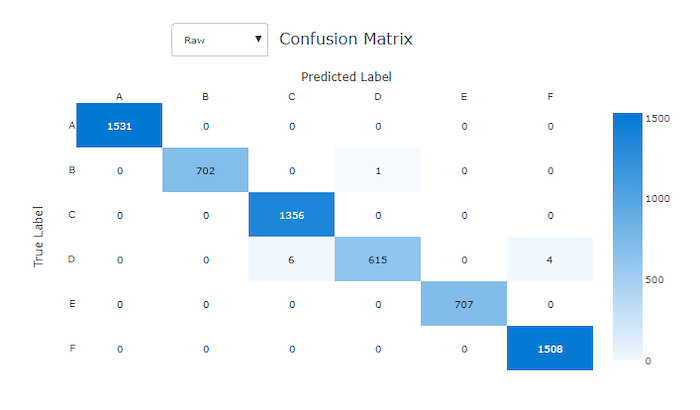 Example

In [27]:
from IPython.display import Image as IPyImage, display
from urllib.parse import urlparse
from urllib.request import urlretrieve

# Confusion matrix
def confusion(y_true, y_pred):
    tp = int(((y_true == 1) & (y_pred == 1)).sum())# Real spam
    fp = int(((y_true == 0) & (y_pred == 1)).sum())# FAlse detected spam
    fn = int(((y_true == 1) & (y_pred == 0)).sum())# Not detected spam
    tn = int(((y_true == 0) & (y_pred == 0)).sum())# Real ham
    return tp, fp, fn, tn

# Calcul precision / rappel (nbr of detected spam) / harmonic average (between precision and rappel)
def prf(y_true, y_pred):
    tp, fp, fn, tn = confusion(y_true, y_pred)
    # Precision [real detected spam]/[real detected spam + false detected spam] 
    # Rôle : Mesure la proportion de messages réellement spams parmi tous ceux 
    # qui ont été prédits comme spams (évite les faux positifs).
    p = tp / (tp + fp) if tp + fp else 0.0
    # Recall [real detected spam]/[real detected spam]/[real detected spam + not detected spam] 
    # Rôle : Mesure la proportion de spams réels qui ont été détectés par le modèle (évite les faux négatifs). 
    r = tp / (tp + fn) if tp + fn else 0.0
    # score : harmonic average : penalize if one of the 2 values is bad
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f1

In [28]:
pred = nb.predict(C_test)
p, r, f1 = prf(y_test, pred)
print(f"precision {p:.3f}  recall {r:.3f}  F1 {f1:.3f}   confusion (tp, fp, fn, tn) = {confusion(y_test, pred)}")
assert abs(p - precision_score(y_test, pred)) < 1e-12 and abs(r - recall_score(y_test, pred)) < 1e-12
print("metrics OK")

precision 0.961  recall 0.953  F1 0.957   confusion (tp, fp, fn, tn) = (123, 5, 6, 890)
metrics OK


**Question E1.** A filter that predicts *ham* for every message: what are its accuracy, precision and recall on this test set?
Which metric exposes it?

### Operating point

A mail provider prefers to let some spam through rather than block a real message. Find the **lowest threshold** on
$P(\text{spam}\mid\mathbf{x})$ for which the precision is at least 0.99, and report the recall at that threshold.

In [29]:
proba = nb.predict_proba(C_test)[:, 1] # select only spam
prec, rec, thr = precision_recall_curve(y_test, proba) # initialy the threshold is 0.5
i = int(np.where(prec[:-1] >= 0.99)[0][0])
threshold, recall_at = float(thr[i]), float(rec[i])
print(f"threshold {threshold}, recall at that threshold {recall_at}")

threshold 0.9924796392365005, recall at that threshold 0.9302325581395349


## Part F. TF-IDF

For a term $t$ in document $d$ with raw count $c_{t,d}$ and $N$ training documents:

$$
\text{tf}=1+\ln c_{t,d}\ (c>0),\qquad \text{idf}(t)=\ln\frac{1+N}{1+\text{df}(t)}+1,\qquad
\mathbf{x}_d\leftarrow\frac{\text{tf}\cdot\text{idf}}{\lVert\text{tf}\cdot\text{idf}\rVert_2}
$$

Transformer du texte brut en vecteur numérique exploitable par des algorithmes.

1. Fréquence du terme sous-linéaire ($\text{tf}$)$$\text{tf} = 1 + \ln c_{t,d} \quad (\text{pour } c_{t,d} > 0)$$Rôle : Mesurer la présence du mot $t$ dans le document $d$ à partir de son nombre d'occurrences brutes $c_{t,d}$. Si $c_{t,d} = 0$, alors $\text{tf} = 0$.Principe de l'échelle logarithmique : Un terme apparaissant 10 fois dans un document n'est pas 10 fois plus important qu'un terme apparaissant 1 seule fois. Le logarithme naturel ($\ln$) comprime cette échelle pour éviter que la fréquence brute ne domine excessivement le score.
2. Fréquence inverse dans les documents ($\text{idf}$)$$\text{idf}(t) = \ln\left(\frac{1+N}{1+\text{df}(t)}\right) + 1$$Variables :$N$ : nombre total de documents dans le jeu d'entraînement.$\text{df}(t)$ : nombre de documents contenant le terme $t$ (Document Frequency).

Rôle : Mesurer la rareté du mot dans tout le corpus.Mots fréquents / grammaticaux (ex: "le", "de", "est") : $\text{df}(t) \approx N$. Le ratio $\frac{1+N}{1+\text{df}(t)}$ tend vers $1$, son logarithme tend vers $0$, et $\text{idf} \approx 1$ (faible poids).Mots spécifiques / rares (ex: "quantique" ou "pédiatrie") : $\text{df}(t)$ est petit, le ratio devient grand, ce qui augmente la valeur de $\text{idf}$ (fort poids).Lissage : Le $+1$ au numérateur et au dénominateur évite la division par zéro (lissage de Laplace), tandis que le $+1$ final garantit qu'un mot présent dans tous les documents conserve un $\text{idf}$ strictement positif.

3. Normalisation $L_2$ du vecteur document$$\mathbf{x}_d \leftarrow \frac{\text{tf}\cdot\text{idf}}{\lVert\text{tf}\cdot\text{idf}\rVert_2}$$Rôle : Diviser chaque composante du vecteur $\text{tf} \cdot \text{idf}$ par sa norme euclidienne $\lVert \mathbf{v} \rVert_2 = \sqrt{\sum v_i^2}$.Pourquoi est-ce indispensable ?Indépendance vis-à-vis de la longueur : Un document très long contient naturellement plus de mots qu'un texte court. Sans cette normalisation, les documents longs auraient des normes démesurées.Simplicité géométrique : Le vecteur résultant $\mathbf{x}_d$ est ramené à une longueur de $1$ ($\lVert \mathbf{x}_d \rVert_2 = 1$). Calculer la similarité cosinus entre deux documents $d_1$ et $d_2$ revient alors à un produit scalaire direct : $\text{sim}(d_1, d_2) = \mathbf{x}_{d_1} \cdot \mathbf{x}_{d_2}$.

Measure the importance of a word according to the rest of the message.
TF = frequency of the word
IDF = a which point a worrd is rare in a message
TF * IDF = weight 
the method is to reduce the weight of common word and increase the distinctive words

In [30]:
# C counter matrix
def tfidf_fit(C):
    """Return the idf vector computed on the TRAINING counts."""
    # Get le nombre de messages
    N = C.shape[0]
    # TODO: df = number of documents containing each word ((C > 0).sum(axis=0)); return the idf formula above
    # Transform C matric to get a boolean matrix where =1 if the word is detected and =0 otherwise
    df_ = np.asarray((C > 0).sum(axis=0)).ravel()
    # apply of the calcul
    return np.log((1 + N) / (1 + df_)) + 1


def tfidf_transform(C, idf):
    T = C.tocsr().copy()
    # TODO 1: sublinear tf: T.data = 1 + ln(T.data)
    T.data = 1.0 + np.log(T.data)
    # TODO 2: multiply the columns by idf (T @ sp.diags(idf))
    T = T @ sp.diags(idf)
    # TODO 3: L2-normalise every row    
    norms = np.sqrt(np.asarray(T.multiply(T).sum(axis=1)).ravel())
    norms[norms == 0] = 1.0
    return sp.diags(1.0 / norms) @ T

In [31]:
# check: must agree with scikit-learn
idf = tfidf_fit(C_train)
T_train, T_test = tfidf_transform(C_train, idf), tfidf_transform(C_test, idf)
ref_t = TfidfTransformer(sublinear_tf=True).fit(C_train)
err = abs(ref_t.transform(C_test) - T_test).max()
print("max |ours - sklearn| =", err)
assert err < 1e-9
print("TF-IDF OK")
order = np.argsort(idf)
print("lowest idf :", [vocab[i] for i in order[:8]])
print("highest idf:", [vocab[i] for i in order[-5:]])

max |ours - sklearn| = 2.220446049250313e-16
TF-IDF OK
lowest idf : ['i', 'to', 'you', 'a', 'the', '!', 'u', 'and']
highest idf: ['kz', 'lag', 'yor', 'yunny', 'zoe']


**Question F1.** Why are `you`, `to`, `the` at the bottom of the idf list, and what does that do to their weight?

Because they are not rare and relevent for detecting spam.

This method is not a method to classify data but more to represent better the vectors of words. The purpose is to add some weight at specific words.

## Part G. Compare the models (report table)

Train Naive Bayes on the **counts** and on the **TF-IDF** matrix, with $k=0.1$ and $k=1$, and fill in the table
(precision, recall, F1 on the test set). Which representation is better? Is the difference larger than the noise? (Repeat the
split with 3 different `random_state` values to estimate it; optional if you are short of time.)

In [32]:
rows = {}
# TODO: for name, (A, B) in {"counts": (C_train, C_test), "tf-idf": (T_train, T_test)}.items() and k in (0.1, 1.0):
#       fit NaiveBayes(k) on A, predict B, store prf(y_test, pred) in rows[f"{name} k={k}"]
for name, (A, B) in {"counts": (C_train, C_test), "tf-idf": (T_train, T_test)}.items():
    for k in (0.1, 1.0):
        m = NaiveBayes(k).fit(A, y_train)
        rows[f"{name} k={k}"] = prf(y_test, m.predict(B))
for name, (p, r, f1) in rows.items():
    print(f"{name:18} precision {p:.3f}  recall {r:.3f}  F1 {f1:.3f}")

counts k=0.1       precision 0.953  recall 0.953  F1 0.953
counts k=1.0       precision 0.961  recall 0.953  F1 0.957
tf-idf k=0.1       precision 0.968  recall 0.930  F1 0.949
tf-idf k=1.0       precision 0.991  recall 0.829  F1 0.903


Better result whatever k with tf-idf method.

## Part H. Logistic regression from scratch (JAX)

Naive Bayes estimates each word's weight from counts. **Logistic regression** learns all the weights *together* by minimising a
loss with gradient descent. Model: $z=\mathbf{w}\cdot\mathbf{x}+b$, $P(\text{spam})=\sigma(z)$; loss with an L2 penalty:

$$
J=-\frac1n\sum_i\big[y_i\log\sigma(z_i)+(1-y_i)\log\sigma(-z_i)\big]+\frac\lambda2\lVert\mathbf{w}\rVert^2
$$

**Use `jax.nn.log_sigmoid`**: `log(sigmoid(z))` is `-inf` for $z=-800$. The features are your TF-IDF matrices of Part F.

Cette partie introduit la Régression Logistique entraînée avec JAX, un algorithme d'apprentissage supervisé discriminatif qui vient contraster avec l'approche générative de Naïve Bayes.Au lieu de calculer des probabilités à partir de simples comptages indépendants pour chaque mot, la régression logistique optimise tous les poids conjointement par descente de gradient.1. Le Modèle : Score linéaire et SigmoïdePour un document représenté par son vecteur TF-IDF $\mathbf{x}$, le modèle calcule d'abord un score scalaire $z$ :$$z = \mathbf{w} \cdot \mathbf{x} + b$$$\mathbf{w}$ est le vecteur des poids (un poids par mot du vocabulaire).$b$ est le biais (bias).Ce score $z \in ]-\infty, +\infty[$ est ensuite transformé en une probabilité $P(\text{spam}) \in [0, 1]$ grâce à la fonction sigmoïde $\sigma(z) = \frac{1}{1 + e^{-z}}$ :$$P(\text{spam} \mid \mathbf{x}) = \sigma(z)$$2. La Fonction de Perte $J$ (Entropie Croisée + Régularisation $L_2$)La formule de la perte regroupe deux éléments essentiels :$$J = -\frac{1}{n}\sum_{i=1}^n \Big[ y_i \log \sigma(z_i) + (1-y_i) \log \sigma(-z_i) \Big] + \frac{\lambda}{2} \lVert\mathbf{w}\rVert^2$$A. L'Entropie Croisée Binaire (Binary Cross-Entropy)Pour un exemple $i$ avec label réel $y_i \in \{0, 1\}$ :Si $y_i = 1$ (spam) : la perte vaut $-\log \sigma(z_i)$. On veut que $\sigma(z_i) \to 1$, donc $z_i \to +\infty$.Si $y_i = 0$ (non-spam) : la perte vaut $-\log(1 - \sigma(z_i))$.Propriété clé de la sigmoïde : $1 - \sigma(z) = \sigma(-z)$.C'est pourquoi la formule s'écrit de manière très propre avec $\log \sigma(-z_i)$ pour le cas $y_i = 0$.B. La Régularisation $L_2$ ($\frac{\lambda}{2} \lVert\mathbf{w}\rVert^2$)Elle pénalise les poids $\mathbf{w}$ trop grands.Sans régularisation, si un mot apparaît uniquement dans des spams, le modèle attribuerait à ce mot un poids $\mathbf{w}_j \to +\infty$, créant du surapprentissage (overfitting). Le paramètre $\lambda > 0$ contrôle la force de cette pénalité.3. La Stabilité Numérique avec jax.nn.log_sigmoidC'est le point d'attention majeur indiqué dans la consigne :Le problème naïf : Si $z = -800$, la sigmoïde donne $\sigma(-800) = \frac{1}{1 + e^{800}} \approx 0$. Prendre ensuite le logarithme $\log(0)$ produit une erreur $-\infty$ ou un NaN lors du calcul des dérivées dans JAX.La solution : jax.nn.log_sigmoid(z) calcule directement $\log \sigma(z)$ en utilisant l'identité mathématique :$$\log \sigma(z) = -\ln(1 + e^{-z})$$En ajustant le calcul selon le signe de $z$, cette fonction évite les débordements de capacité (overflow/underflow) et garantit des gradients stables.

In [33]:
A_train = jnp.asarray(T_train.toarray())
A_test = jnp.asarray(T_test.toarray())
y_tr = jnp.asarray(y_train, dtype=jnp.float64)
LAM = 1e-5


def loss(params, X, y, lam=LAM):
    w, b = params
    z = X @ w + b
    nll = -jnp.mean(y * jax.nn.log_sigmoid(z) + (1 - y) * jax.nn.log_sigmoid(-z))
    return nll + 0.5 * lam * jnp.dot(w, w)

In [34]:
# check 1: the loss at w=0, b=0 must be ln 2
p0 = (jnp.zeros(A_train.shape[1]), 0.0)
assert abs(float(loss(p0, A_train, y_tr)) - np.log(2)) < 1e-9
# check 2: the autodiff gradient must match the analytic one
g_w, _ = jax.grad(loss)(p0, A_train, y_tr)
g_hand = A_train.T @ (jax.nn.sigmoid(A_train @ p0[0] + p0[1]) - y_tr) / len(y_tr)
assert float(jnp.abs(g_w - g_hand).max()) < 1e-9
print("loss and gradient OK")

loss and gradient OK


Now the optimiser: plain **gradient descent**, $\theta\leftarrow\theta-\eta\nabla J$.

In [36]:
loss_and_grad = jax.jit(jax.value_and_grad(loss))


def gradient_descent(X, y, eta=50.0, steps=300):
    params = (jnp.zeros(X.shape[1]), 0.0)
    history = []
    for _ in range(steps):
        value, g = loss_and_grad(params, X, y)
        params = (params[0] - eta * g[0], params[1] - eta * g[1])
        history.append(float(value))
    return params, history


params, history = gradient_descent(A_train, y_tr)
print("loss:", history[0], "->", history[-1])
assert history[-1] < history[0] * 0.5
score_lr = np.asarray(A_test @ params[0] + params[1])
pred_lr = (score_lr >= 0).astype(int)
p, r, f1 = prf(y_test, pred_lr)
print(f"logistic regression (GD): precision {p:.3f}  recall {r:.3f}  F1 {f1:.3f}")

loss: 0.6931471805599447 -> 0.03565195907271411
logistic regression (GD): precision 0.975  recall 0.907  F1 0.940


lower of loss :

before 50% for each class

to get a better regression (more spaced)

**Question H1.** Plot the loss history for $\eta=1$, $50$ and $500$ (use the cell below). Describe and explain each behaviour.

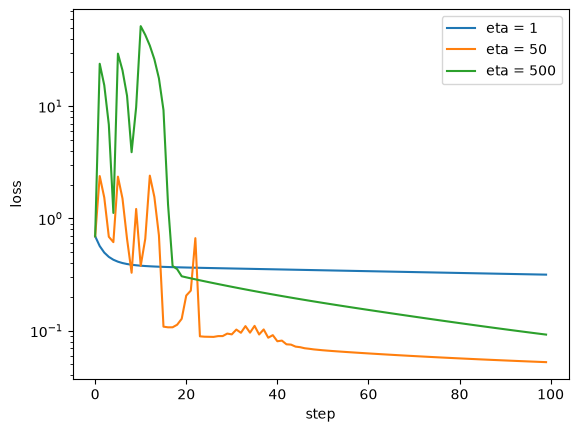

In [38]:
# TODO: for eta in (1, 50, 500): _, h = gradient_descent(A_train, y_tr, eta=eta, steps=100); plot h (log y axis), add a legend
for eta in (1, 50, 500):
    _, h = gradient_descent(A_train, y_tr, eta=eta, steps=100)
    plt.plot(h, label=f"eta = {eta}")
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.show()

eta est le taux d’apprentissage de la descente de gradient.

Il contrôle la taille du pas quand on met à jour les poids :
θ
←
θ
−
η
∇
J
θ←θ−η∇J

eta petit, comme 1 : apprentissage lent, mais souvent stable.
eta moyen, comme 50 : peut converger plus vite si le problème est bien conditionné.
eta trop grand, comme 500 : risque d’osciller ou de diverger, parce qu’on “saute” trop loin à chaque itération.
Dans ton graphique, eta sert donc à comparer la stabilité et la vitesse de convergence de l’optimisation.

## Part I. What did the models learn?

List the 10 words with the highest and the lowest weight in each model: the **log-odds** $\log P(w\mid\text{spam})-\log P(w\mid\text{ham})$
of Naive Bayes and the **weights** of the logistic regression.

In [40]:
# TODO: NB: odds = nb.log_lik_[1] - nb.log_lik_[0]; LR: w = np.asarray(params[0]); print the top-10 and bottom-10 words of both (np.argsort)
odds = nb.log_lik_[1] - nb.log_lik_[0]
o = np.argsort(odds)
print("NB  spammy:", [vocab[i] for i in o[::-1][:10]])
print("NB  hammy :", [vocab[i] for i in o[:10]])
w = np.asarray(params[0])
o = np.argsort(w)
print("LR  spammy:", [vocab[i] for i in o[::-1][:10]])
print("LR  hammy :", [vocab[i] for i in o[:10]])

NB  spammy: ['claim', 'num', 'prize', 'uk', 'ppm', 'guaranteed', 'www', 'tone', 'co', 'cs']
NB  hammy : ['gt', 'lt', 'he', 'lor', 'she', 'sorry', 'where', 'later', 'wat', 'ask']
LR  spammy: ['num', 'p', 'txt', 'text', 'free', 'mobile', 'call', 'reply', 'stop', 'www']
LR  hammy : ['i', 'my', 'me', 'lt', 'gt', 'can', 'then', 'that', 'it', 'ok']


**Question I1.** Some "hammy" words (`lt`, `gt`) are not evidence of legitimacy; where do they come from? What does that say about
the model, and how could an attacker use this list?

html transform to raw text produce these words (dangerous)

**Question I2.** The weight vector of the logistic regression is the gradient of its score with respect to the input. What would an attacker need to know, and do, to use it against the filter?

He need to know the weight